# Measuring ambiguity in public market data

## Monthly Priors from a Public Daily Series

For year \(y\) and month \(m\), the monthly mean and population standard deviation are

$$
\mu_{y,m}=\frac{1}{n_{y,m}}\sum_{t\in\mathcal I_{y,m}}r_t,
\qquad
\sigma_{y,m}=\left[\frac{1}{n_{y,m}}\sum_{t\in\mathcal I_{y,m}}(r_t-\mu_{y,m})^2\right]^{1/2}.
$$

Here, \(\mathcal I_{y,m}\) is the set of valid daily returns in month \(m\) of year \(y\); \(n_{y,m}\) is its size; \(r_t\) is the daily log return; \(\mu_{y,m}\) is its mean; and \(\sigma_{y,m}\) is its population standard deviation. The twelve fitted normal laws are supplied to the ambiguity calculation with equal default weights. They are teaching approximations, not observations of investor beliefs.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("04_probability_ambiguity");
using CSV, Printf
using RiskLabAI.Features: probability_ambiguity, normal_prior_bin_probabilities

function load_public_data()
    data_path = dataset_path("fred_nasdaq")
    @assert isfile(data_path)
    raw = CSV.read(data_path,DataFrame;missingstring=["", "."])
    data = dropmissing(raw,:NASDAQCOM)
    sort!(data,:observation_date)
    rename!(data,:observation_date=>"Date",:NASDAQCOM=>"NASDAQ Composite")
    data.Date = Date.(data.Date)
    prices = data[!,"NASDAQ Composite"]
    data[!,"Daily log return"] = vcat(NaN,log.(prices[2:end]./prices[1:end-1]))
    data.Year = year.(data.Date)
    data.Month = month.(data.Date)
    return data
end

function monthly_moments(data)
    returns = data[isfinite.(data[!,"Daily log return"]),:]
    return combine(groupby(returns,[:Year,:Month];sort=true),"Daily log return"=>mean=>:Mean,"Daily log return"=>(values->std(values;corrected=false))=>:Standard_deviation,"Daily log return"=>length=>:Observations)
end

normal_edges(width) = collect(range(-.06,.06;length=round(Int,.12/width)+1))
percent_label(value) = @sprintf("%g%%",100value)
bin_labels(edges) = vcat("Below "*percent_label(first(edges)),[percent_label(left)*" to "*percent_label(right) for (left,right) in zip(edges[1:end-1],edges[2:end])],"Above "*percent_label(last(edges)))


bin_labels (generic function with 1 method)

In [2]:
data = load_public_data()
returns = data[isfinite.(data[!,"Daily log return"]),:]
moments = monthly_moments(data)
provenance = DataFrame("Item"=>["Series","Provider","Source institution","Frequency","Local period","Download during run"],"Value"=>["NASDAQ Composite (NASDAQCOM)","Federal Reserve Economic Data","Nasdaq, Inc.","Daily close",string(first(data.Date)," to ",last(data.Date)),"No"])
save_table(provenance,paths,"data_provenance";caption="Public data and fixed local file identity.",label="tab:chapter5-ambiguity-data-provenance")
data_summary = DataFrame("Quantity"=>["Valid index levels","Daily log returns","Calendar months","Complete calendar years","Fewest returns in a month","Most returns in a month"],"Value"=>[nrow(data),nrow(returns),nrow(moments),length(unique(moments.Year)),minimum(moments.Observations),maximum(moments.Observations)])
save_table(data_summary,paths,"public_data_summary";caption="Counts in the public daily NASDAQ Composite sample.",label="tab:chapter5-public-data-summary")
history = select(data,"Date","NASDAQ Composite","Daily log return")
history[!,"Daily log return (%)"] = 100 .* history[!,"Daily log return"]
save_data(history,paths,"public_price_return_history")
save_data(moments,paths,"monthly_moments");


Row,Item,Value
,String,String
1,Series,NASDAQ Composite (NASDAQCOM)
2,Provider,Federal Reserve Economic Data
3,Source institution,"Nasdaq, Inc."
4,Frequency,Daily close
5,Local period,1994-01-03 to 2025-12-31
6,Download during run,No


Row,Quantity,Value
,String,Int64
1,Valid index levels,8055
2,Daily log returns,8054
3,Calendar months,384
4,Complete calendar years,32
5,Fewest returns in a month,15
6,Most returns in a month,23


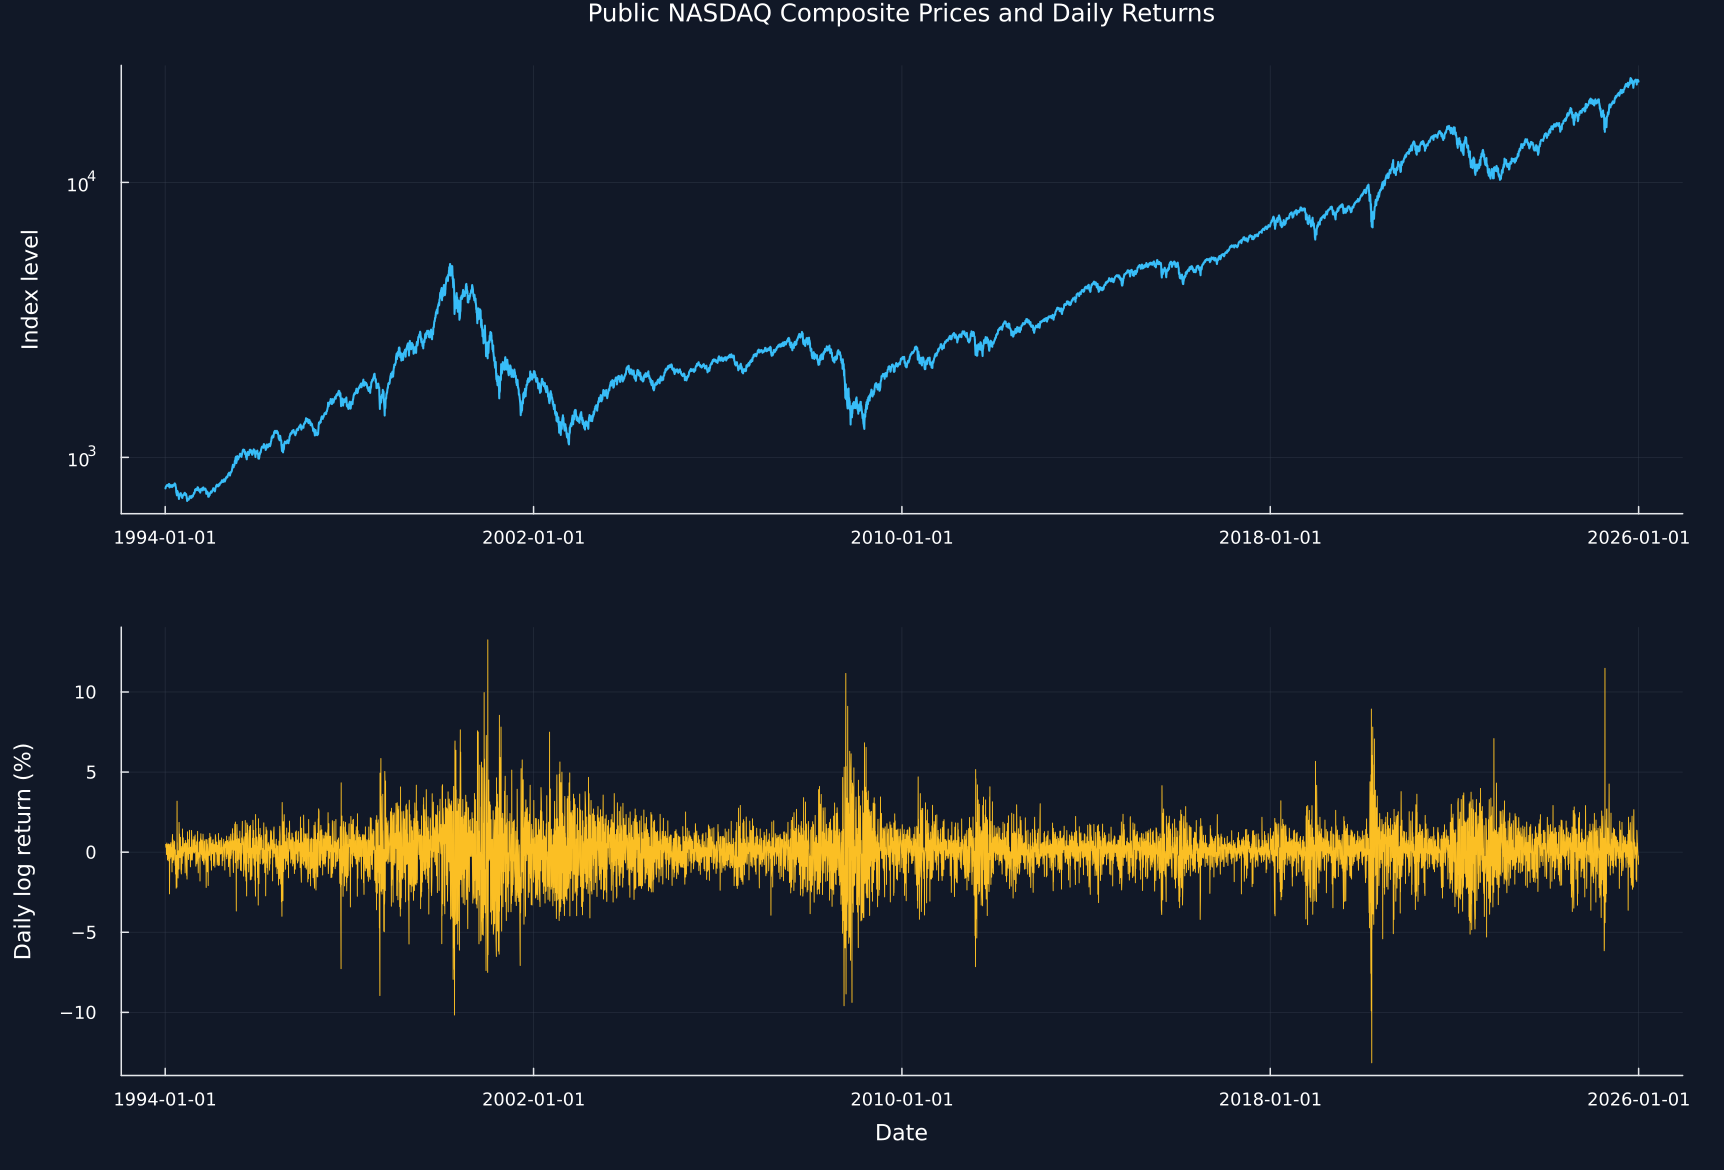

In [3]:
top = plot(history.Date,history[!,"NASDAQ Composite"];yscale=:log10,color=palette.cyan,linewidth=1.35,ylabel="Index level",title="Public NASDAQ Composite Prices and Daily Returns",label=false)
bottom = plot(history.Date,history[!,"Daily log return (%)"];color=palette.amber,linewidth=.62,ylabel="Daily log return (%)",xlabel="Date",label=false)
save_figure(plot(top,bottom;layout=(2,1),size=(1150,780)),paths,"public_price_return_history")


## Why ambiguity and return risk describe different features

The annual daily return variance is

$$
\sigma_y^2=\frac{1}{n_y}\sum_{t\in\mathcal I_y}(r_t-\bar r_y)^2,
\qquad
\bar r_y=\frac{1}{n_y}\sum_{t\in\mathcal I_y}r_t.
$$

Here, \(\mathcal I_y\) is the set of daily returns in year \(y\); \(n_y\) is the number of those returns; \(\bar r_y\) is their mean; and \(\sigma_y\) is their population standard deviation. This risk summary concerns variation in realized daily outcomes. The ambiguity summary concerns disagreement among twelve fitted monthly probability laws. Neither quantity determines the other.

In [4]:
edges = normal_edges(.002)
annual_rows = NamedTuple[]
for year_moments in groupby(moments,:Year;sort=true)
    calendar_year = first(year_moments.Year)
    @assert nrow(year_moments) == 12
    probabilities = normal_prior_bin_probabilities(year_moments.Mean,year_moments.Standard_deviation;edges)
    ambiguity = probability_ambiguity(probabilities;bin_width=.002)
    year_returns = returns[returns.Year.==calendar_year,"Daily log return"]
    push!(annual_rows,(;year=calendar_year,laws=nrow(year_moments),observations=length(year_returns),unscaled=ambiguity.unscaled,scaled=ambiguity.scaled,risk=100std(year_returns;corrected=false)))
end
annual = DataFrame(annual_rows)
rename!(annual,["Year","Monthly laws","Daily returns","Unscaled ambiguity","Scaled ambiguity","Daily return standard deviation (%)"])
save_table(annual,paths,"annual_ambiguity_series";caption="Annual probability ambiguity and daily return risk from the public series.",label="tab:chapter5-annual-ambiguity-series")
save_data(annual,paths,"annual_ambiguity_series")
largest = first(sort(annual,"Scaled ambiguity";rev=true),5)
smallest = first(sort(annual,"Scaled ambiguity"),5)
largest.Group = fill("Five largest ambiguity values",5)
smallest.Group = fill("Five smallest ambiguity values",5)
extremes = vcat(largest,smallest)[:,["Group","Year","Scaled ambiguity","Daily return standard deviation (%)"]]
save_table(extremes,paths,"descriptive_ambiguity_extremes";caption="Years with the five largest and five smallest ambiguity values.",label="tab:chapter5-descriptive-ambiguity-extremes")
correlation = cor(annual[!,"Scaled ambiguity"],annual[!,"Daily return standard deviation (%)"])
relation = DataFrame("Quantity"=>["Years","First year","Last year","Correlation between annual summaries","Largest ambiguity year","Largest risk year"],"Value"=>string.(Any[nrow(annual),minimum(annual.Year),maximum(annual.Year),correlation,annual.Year[argmax(annual[!,"Scaled ambiguity"])],annual.Year[argmax(annual[!,"Daily return standard deviation (%)"])]]))
save_table(relation,paths,"risk_ambiguity_relation";caption="Descriptive relation between annual return risk and probability ambiguity.",label="tab:chapter5-risk-ambiguity-relation")


Row,Year,Monthly laws,Daily returns,Unscaled ambiguity,Scaled ambiguity,Daily return standard deviation (%)
,Int64,Int64,Int64,Float64,Float64,Float64
1,1994,12,251,0.000797964,0.399782,0.729229
2,1995,12,252,0.000555812,0.278463,0.838085
3,1996,12,254,0.00034407,0.17238,0.969899
4,1997,12,253,0.000215154,0.107793,1.16458
5,1998,12,252,0.000242575,0.12153,1.66958
6,1999,12,252,5.24973e-5,0.0263013,1.71499
7,2000,12,252,0.0001443,0.0722944,3.065
8,2001,12,248,7.8072e-5,0.0391142,2.72275
9,2002,12,252,3.48822e-5,0.017476,2.15853


Row,Group,Year,Scaled ambiguity,Daily return standard deviation (%)
,String,Int64,Float64,Float64
1,Five largest ambiguity values,2014,0.427694,0.890644
2,Five largest ambiguity values,1994,0.399782,0.729229
3,Five largest ambiguity values,2019,0.305016,0.983242
4,Five largest ambiguity values,2016,0.290353,1.00252
5,Five largest ambiguity values,1995,0.278463,0.838085
6,Five smallest ambiguity values,2003,0.0155863,1.60283
7,Five smallest ambiguity values,2022,0.0163763,2.0097
8,Five smallest ambiguity values,2002,0.017476,2.15853
9,Five smallest ambiguity values,1999,0.0263013,1.71499


Row,Quantity,Value
,String,String
1,Years,32
2,First year,1994
3,Last year,2025
4,Correlation between annual summaries,-0.5494492000814872
5,Largest ambiguity year,2014
6,Largest risk year,2000


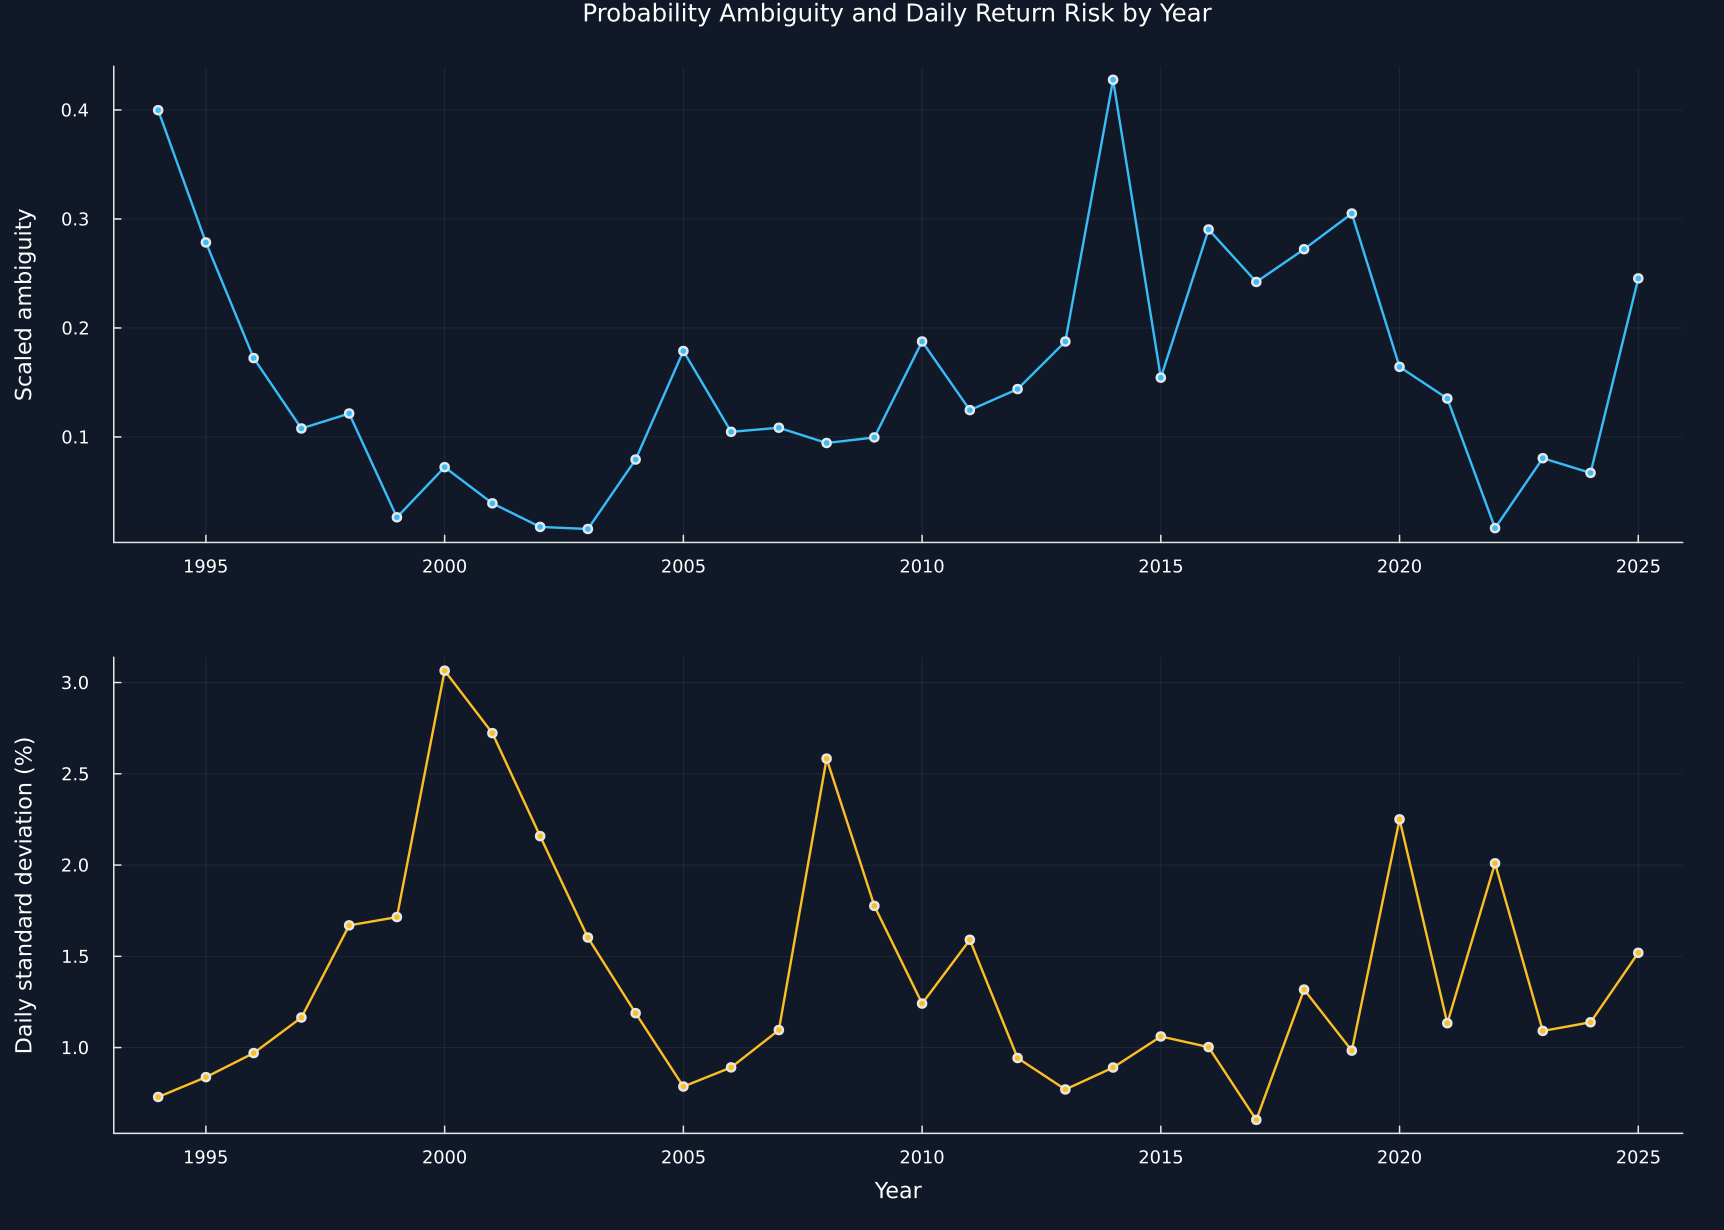

In [5]:
top = plot(annual.Year,annual[!,"Scaled ambiguity"];color=palette.cyan,marker=:circle,markersize=3,linewidth=1.6,ylabel="Scaled ambiguity",title="Probability Ambiguity and Daily Return Risk by Year",label=false)
bottom = plot(annual.Year,annual[!,"Daily return standard deviation (%)"];color=palette.amber,marker=:circle,markersize=3,linewidth=1.6,ylabel="Daily standard deviation (%)",xlabel="Year",label=false)
save_figure(plot(top,bottom;layout=(2,1),size=(1150,820)),paths,"annual_ambiguity_and_risk")


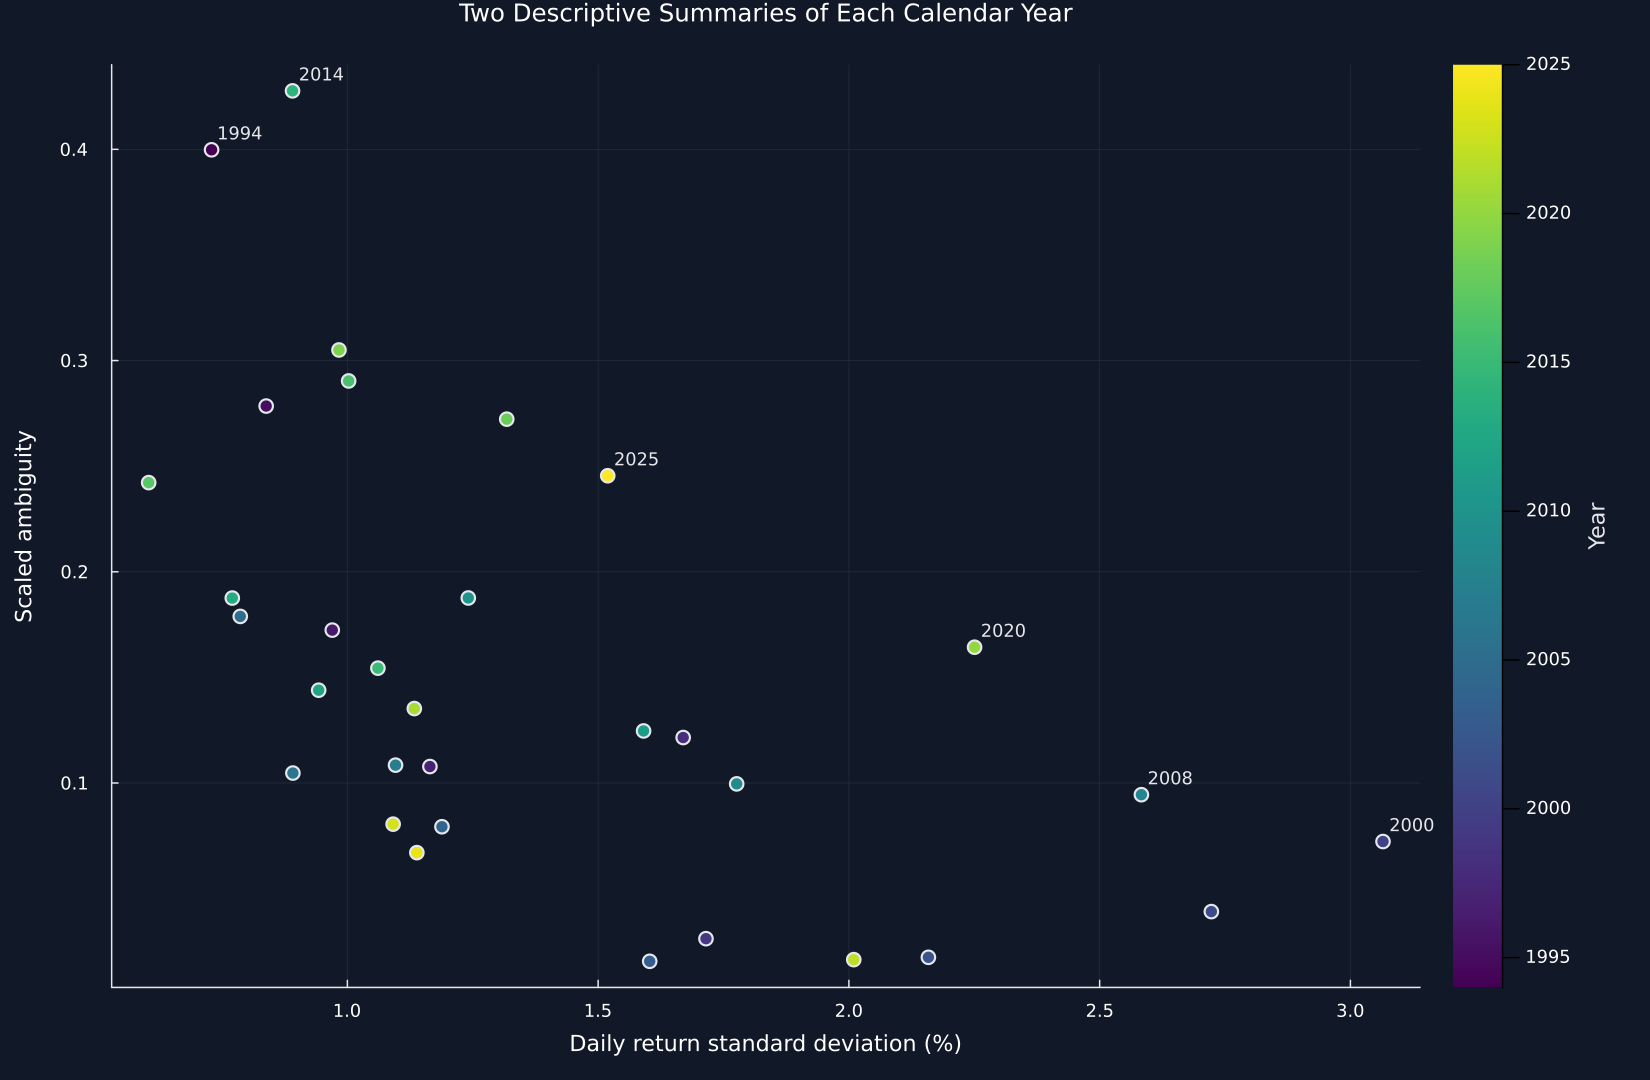

In [6]:
figure = scatter(annual[!,"Daily return standard deviation (%)"],annual[!,"Scaled ambiguity"];marker_z=annual.Year,c=:viridis,markersize=5,colorbar_title="Year",xlabel="Daily return standard deviation (%)",ylabel="Scaled ambiguity",title="Two Descriptive Summaries of Each Calendar Year",label=false,size=(1100,720))
for row in eachrow(annual[in.([value for value in annual.Year],Ref([1994,2000,2008,2014,2020,2025])),:])
    annotate!(figure,row["Daily return standard deviation (%)"]+.015,row["Scaled ambiguity"]+.008,text(string(row.Year),8,palette.text,:left))
end
save_figure(figure,paths,"risk_ambiguity_scatter")


## Testing sensitivity to grid and weights

For a chosen interior width \(h\), the annual scaled value is

$$
A_y^{\mathrm{scaled}}(h)=\frac{\sum_k\bar p_{y,k}(h)v_{y,k}(h)}{h(1-h)}.
$$

Here, \(A_y^{\mathrm{scaled}}(h)\) is the scaled ambiguity value for year \(y\); \(\bar p_{y,k}(h)\) and \(v_{y,k}(h)\) are computed on the grid defined by width \(h\); and \(k\) includes the two tails. Values at several widths reveal remaining grid sensitivity.

Observation count weights are

$$
q_{y,m}^{\mathrm{count}}=\frac{n_{y,m}}{\sum_{\ell=1}^{12}n_{y,\ell}}.
$$

Here, \(n_{y,m}\) is the number of daily returns in month \(m\) of year \(y\). Equal weights treat every month alike, while count weights give slightly more weight to months with more valid daily observations. The comparison is a sensitivity check, not a search for a preferred result.

In [7]:
grid_rows,weight_rows = NamedTuple[],NamedTuple[]
for year_moments in groupby(moments,:Year;sort=true)
    calendar_year = first(year_moments.Year)
    for width in [.001,.002,.004]
        width_edges = normal_edges(width)
        probabilities = normal_prior_bin_probabilities(year_moments.Mean,year_moments.Standard_deviation;edges=width_edges)
        ambiguity = probability_ambiguity(probabilities;bin_width=width)
        push!(grid_rows,(;year=calendar_year,width,interior_bins=length(width_edges)-1,unscaled=ambiguity.unscaled,scaled=ambiguity.scaled))
    end
    default_probabilities = normal_prior_bin_probabilities(year_moments.Mean,year_moments.Standard_deviation;edges)
    equal = probability_ambiguity(default_probabilities;bin_width=.002)
    count_weights = year_moments.Observations./sum(year_moments.Observations)
    count = probability_ambiguity(default_probabilities;prior_weights=count_weights,bin_width=.002)
    push!(weight_rows,(;year=calendar_year,equal=equal.scaled,count=count.scaled,difference=abs(equal.scaled-count.scaled)))
end
grid_sensitivity,weight_sensitivity = DataFrame(grid_rows),DataFrame(weight_rows)
rename!(grid_sensitivity,["Year","Interior bin width","Interior bins","Unscaled ambiguity","Scaled ambiguity"])
rename!(weight_sensitivity,["Year","Equal month weights","Observation count weights","Absolute difference"])
save_data(grid_sensitivity,paths,"grid_sensitivity")
save_data(weight_sensitivity,paths,"weight_sensitivity")
save_table(grid_sensitivity,paths,"grid_sensitivity_all_years";caption="Annual ambiguity values under three interior bin widths.",label="tab:chapter5-grid-sensitivity-all-years")
save_table(weight_sensitivity,paths,"weight_sensitivity_all_years";caption="Annual ambiguity values under equal and observation count weights.",label="tab:chapter5-weight-sensitivity-all-years")
grid_summary = combine(groupby(grid_sensitivity,["Interior bin width","Interior bins"];sort=true),"Scaled ambiguity"=>mean=>"Mean scaled ambiguity","Scaled ambiguity"=>minimum=>"Minimum scaled ambiguity","Scaled ambiguity"=>maximum=>"Maximum scaled ambiguity")
save_table(grid_summary,paths,"grid_sensitivity_summary";caption="Summary across years for three interior bin widths.",label="tab:chapter5-grid-sensitivity-summary")
weight_summary = DataFrame("Quantity"=>["Mean equal weight value","Mean observation count weight value","Mean absolute difference","Largest absolute difference","Year of largest difference"],"Value"=>string.(Any[mean(weight_sensitivity[!,"Equal month weights"]),mean(weight_sensitivity[!,"Observation count weights"]),mean(weight_sensitivity[!,"Absolute difference"]),maximum(weight_sensitivity[!,"Absolute difference"]),weight_sensitivity.Year[argmax(weight_sensitivity[!,"Absolute difference"])]]))
save_table(weight_summary,paths,"weight_sensitivity_summary";caption="Summary of the prior weight sensitivity comparison.",label="tab:chapter5-weight-sensitivity-summary")


Row,Year,Interior bin width,Interior bins,Unscaled ambiguity,Scaled ambiguity
,Int64,Float64,Int64,Float64,Float64
1,1994,0.001,120,0.000204345,0.20455
2,1994,0.002,60,0.000797964,0.399782
3,1994,0.004,30,0.00292072,0.733114
4,1995,0.001,120,0.000141121,0.141262
5,1995,0.002,60,0.000555812,0.278463
6,1995,0.004,30,0.00209117,0.524892
7,1996,0.001,120,8.68605e-5,0.0869474
8,1996,0.002,60,0.00034407,0.17238
9,1996,0.004,30,0.00132397,0.332322


Row,Year,Equal month weights,Observation count weights,Absolute difference
,Int64,Float64,Float64,Float64
1,1994,0.399782,0.402473,0.00269075
2,1995,0.278463,0.278238,0.000224497
3,1996,0.17238,0.171575,0.000804499
4,1997,0.107793,0.109177,0.00138439
5,1998,0.12153,0.118076,0.00345438
6,1999,0.0263013,0.0263117,1.04677e-5
7,2000,0.0722944,0.0695095,0.00278485
8,2001,0.0391142,0.0387174,0.000396801
9,2002,0.017476,0.0175329,5.68903e-5


Row,Interior bin width,Interior bins,Mean scaled ambiguity,Minimum scaled ambiguity,Maximum scaled ambiguity
,Float64,Int64,Float64,Float64,Float64
1,0.001,120,0.0836792,0.00780911,0.218199
2,0.002,60,0.155022,0.0155863,0.427694
3,0.004,30,0.290802,0.0308596,0.791033


Row,Quantity,Value
,String,String
1,Mean equal weight value,0.15502214611379825
2,Mean observation count weight value,0.15499969957118565
3,Mean absolute difference,0.0023157680575997025
4,Largest absolute difference,0.012405308591867947
5,Year of largest difference,2014


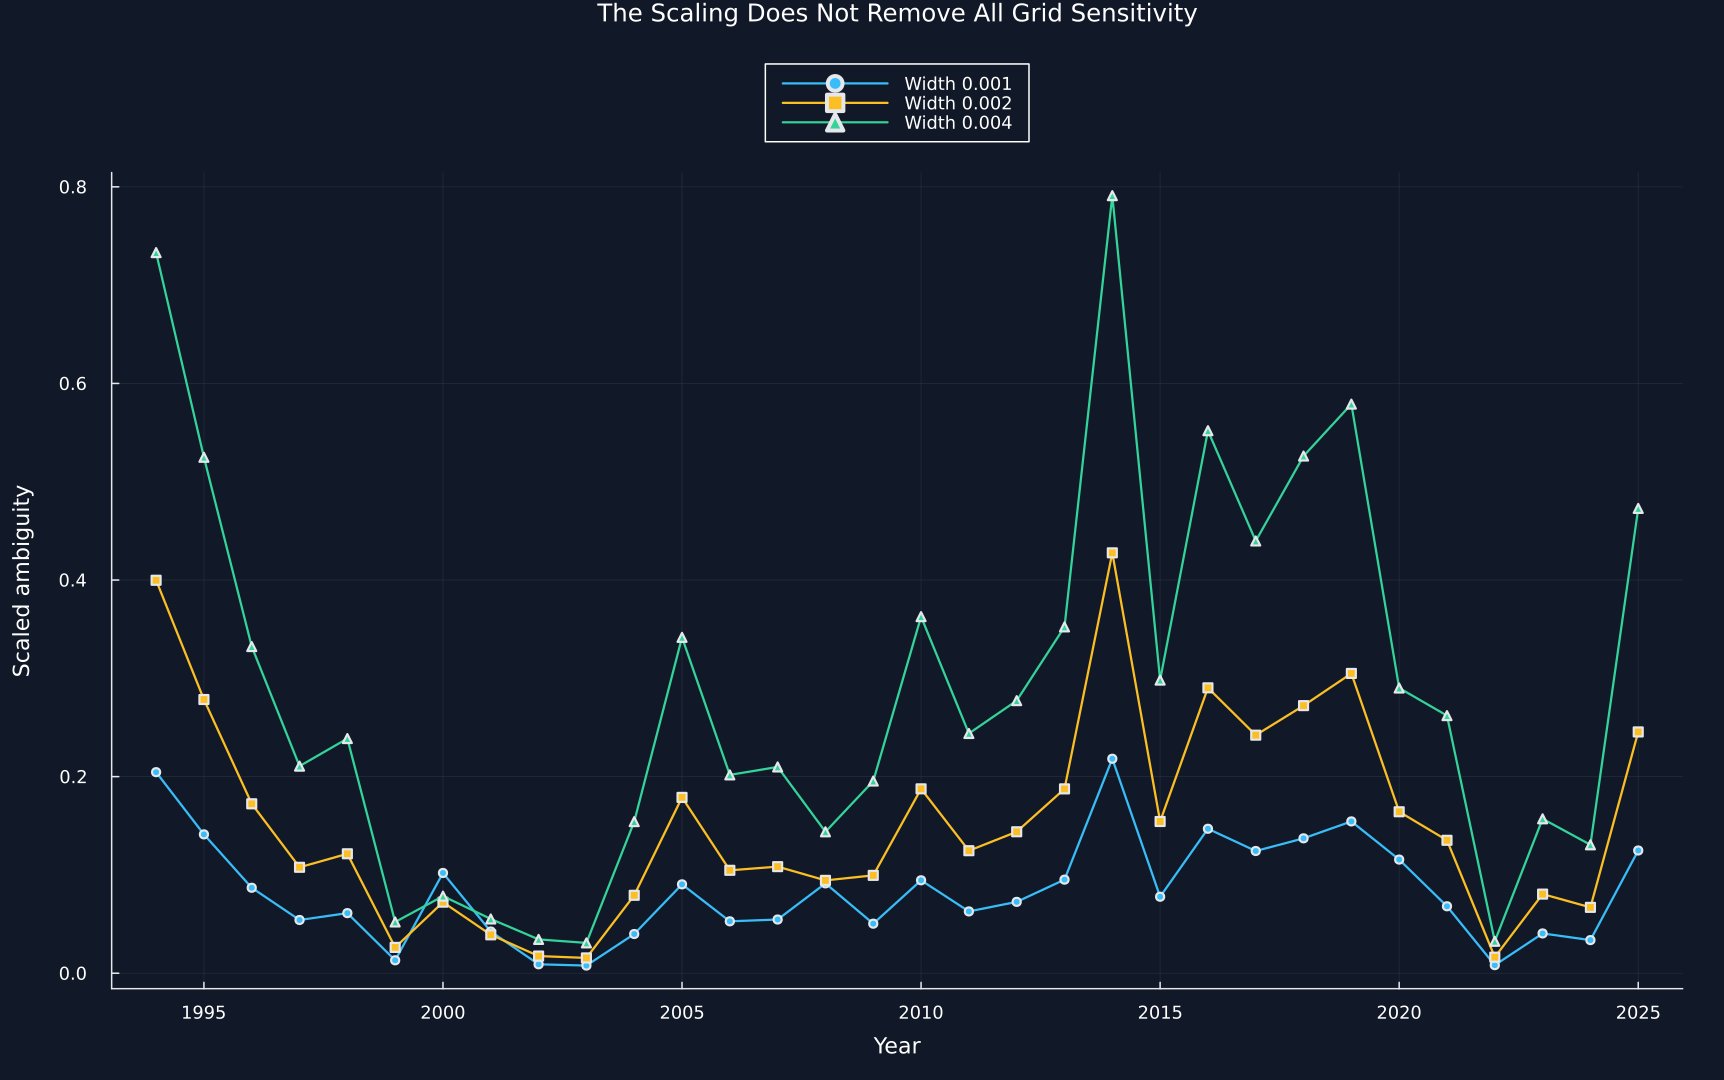

In [8]:
figure = plot(;xlabel="Year",ylabel="Scaled ambiguity",title="The Scaling Does Not Remove All Grid Sensitivity",legend=:outertop,size=(1150,720))
for (width,color,marker) in [(.001,palette.cyan,:circle),(.002,palette.amber,:square),(.004,palette.green,:utriangle)]
    part = grid_sensitivity[grid_sensitivity[!,"Interior bin width"].==width,:]
    plot!(figure,part.Year,part[!,"Scaled ambiguity"];color,marker,markersize=3,linewidth=1.5,label="Width "*string(width))
end
save_figure(figure,paths,"grid_sensitivity")


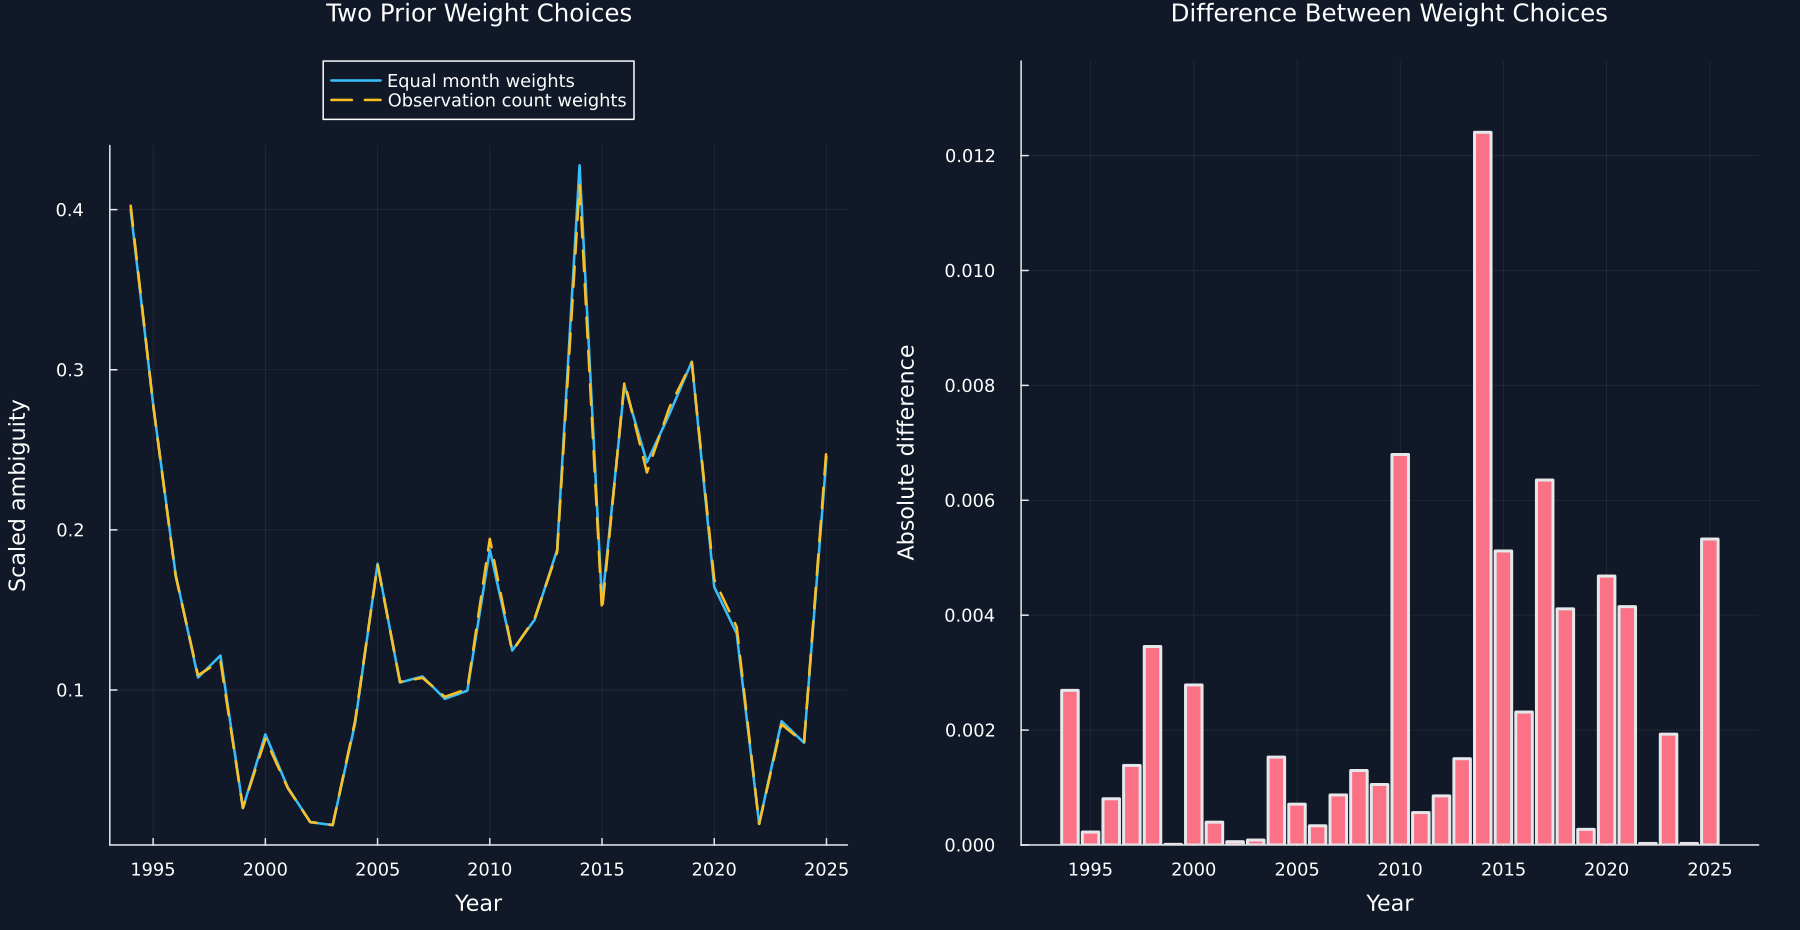

In [9]:
left = plot(weight_sensitivity.Year,weight_sensitivity[!,"Equal month weights"];color=palette.cyan,linewidth=1.7,xlabel="Year",ylabel="Scaled ambiguity",title="Two Prior Weight Choices",label="Equal month weights",legend=:outertop)
plot!(left,weight_sensitivity.Year,weight_sensitivity[!,"Observation count weights"];color=palette.amber,linestyle=:dash,linewidth=1.7,label="Observation count weights")
right = bar(weight_sensitivity.Year,weight_sensitivity[!,"Absolute difference"];color=palette.rose,xlabel="Year",ylabel="Absolute difference",title="Difference Between Weight Choices",ylims=(0,1.1*maximum(weight_sensitivity[!,"Absolute difference"])),label=false)
save_figure(plot(left,right;layout=(1,2),size=(1200,620)),paths,"weight_sensitivity")


In [10]:
worked_direct = monthly_moments(data[data.Year.==1994,:])
stored_worked = moments[moments.Year.==1994,:]
@assert Matrix(worked_direct[:,[:Mean,:Standard_deviation]]) ≈ Matrix(stored_worked[:,[:Mean,:Standard_deviation]])
@assert Set(annual.Year) == Set(1994:2025)
@assert all(annual[!,"Monthly laws"].==12)
@assert sum(annual[!,"Daily returns"]) == nrow(returns)
@assert all(grid_sensitivity[!,"Scaled ambiguity"].>=0)
@assert all(Matrix(weight_sensitivity[:,["Equal month weights","Observation count weights"]]).>=0)
checks = DataFrame("Check"=>["Public file identity","All years contain twelve monthly laws","Annual rows use only returns from their calendar year","Every daily return enters exactly one annual row","All grid sensitivity values are nonnegative","Both prior weight calculations are nonnegative","The worked year is the first complete year by date"],"Result"=>fill("Pass",7))
save_table(checks,paths,"public_example_checks";caption="Checks for the public annual ambiguity example.",label="tab:chapter5-public-example-checks")
limits = DataFrame("Question"=>["What is observed?","What is fitted?","What does ambiguity summarize?","What does return risk summarize?","What is not claimed?"],"Answer"=>["Public daily NASDAQ Composite closing levels","One normal daily return law for each calendar month","Dispersion of bin probabilities across twelve supplied monthly laws","Dispersion of realized daily returns within a calendar year","Investor beliefs, causal effects, pricing results, or investment performance"])
save_table(limits,paths,"interpretation_limits";caption="Interpretation boundary for the public daily illustration.",label="tab:chapter5-interpretation-limits")


Row,Check,Result
,String,String
1,Public file identity,Pass
2,All years contain twelve monthly laws,Pass
3,Annual rows use only returns from their calendar year,Pass
4,Every daily return enters exactly one annual row,Pass
5,All grid sensitivity values are nonnegative,Pass
6,Both prior weight calculations are nonnegative,Pass
7,The worked year is the first complete year by date,Pass


Row,Question,Answer
,String,String
1,What is observed?,Public daily NASDAQ Composite closing levels
2,What is fitted?,One normal daily return law for each calendar month
3,What does ambiguity summarize?,Dispersion of bin probabilities across twelve supplied monthly laws
4,What does return risk summarize?,Dispersion of realized daily returns within a calendar year
5,What is not claimed?,"Investor beliefs, causal effects, pricing results, or investment performance"
